# Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:/Users/49dhe/Desktop/project 2/1_DATA/retail_clean.csv",
                 parse_dates=["InvoiceDate"])
df["Invoice"] = df["Invoice"].astype(str)
df = df[~df["Invoice"].isin(["581483", "541431"])]

# Repeat purchase rate

In [2]:
orders = df.groupby("Customer ID")["Invoice"].nunique()

print("Customers:", len(orders))
print("One-time customers:", (orders == 1).sum())
print("Repeat rate:", round((orders > 1).mean() * 100, 1), "%")

Customers: 5852
One-time customers: 1619
Repeat rate: 72.3 %


# Lable order

In [3]:
df["Month"] = df["InvoiceDate"].dt.strftime("%Y-%m")

first_month = (df.groupby("Customer ID")["Month"].min()
                 .reset_index(name="FirstMonth"))
df = df.merge(first_month, on="Customer ID", how="left")

df["CustomerType"] = "Returning"
df.loc[df["Month"] == df["FirstMonth"], "CustomerType"] = "New"

df[["Customer ID", "Month", "FirstMonth", "CustomerType"]].head()

,Customer ID,Month,FirstMonth,CustomerType
0,13085,2009-12,2009-12,New
1,13085,2009-12,2009-12,New
2,13085,2009-12,2009-12,New
3,13085,2009-12,2009-12,New
4,13085,2009-12,2009-12,New


# Monthly counts and revenue

In [4]:
monthly = df.pivot_table(index="Month", columns="CustomerType",
                         values="Customer ID", aggfunc="nunique")
print(monthly.tail(3))

revenue = df.groupby("CustomerType")["Revenue"].sum()
print((revenue / revenue.sum() * 100).round(1))

CustomerType    New  Returning
Month                         
2011-10       221.0     1140.0
2011-11       191.0     1469.0
2011-12        28.0      585.0
CustomerType
New          17.5
Returning    82.5
Name: Revenue, dtype: float64


# Chart

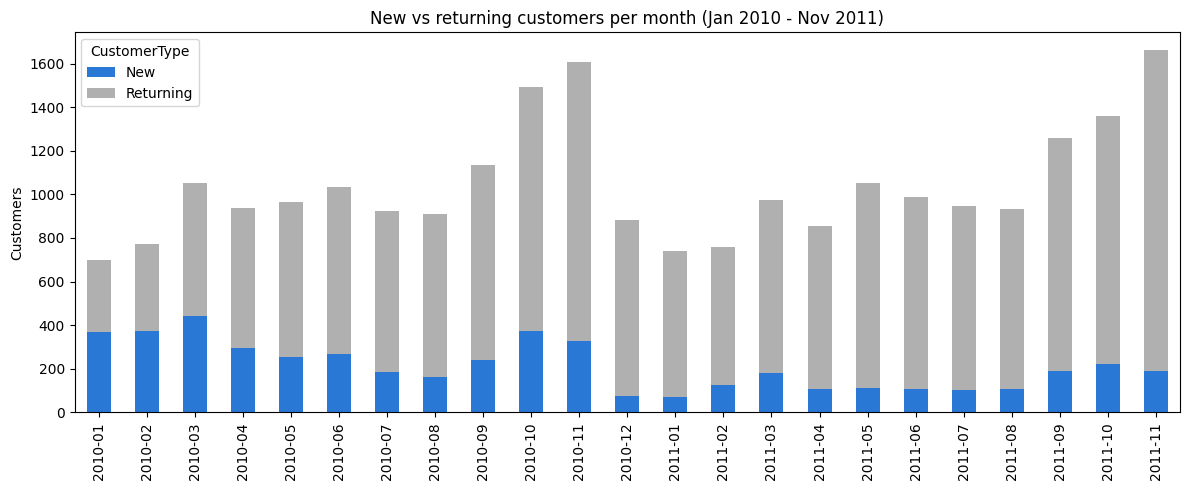

In [5]:
chart = monthly.loc["2010-01":"2011-11"]

ax = chart.plot(kind="bar", stacked=True, figsize=(12, 5),
                color=["#2a78d6", "#b0b0b0"])
ax.set_title("New vs returning customers per month (Jan 2010 - Nov 2011)")
ax.set_xlabel("")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.savefig(r"C:/Users/49dhe/Desktop/project 2/5_IMAGE/new_vs_returning.png", dpi=120)
plt.show()

In [6]:
   monthly.to_csv(r"C:/Users/49dhe/Desktop/project 2/1_DATA/new_vs_returning_monthly.csv")